Step 1: Generating simple 2D data...
Data shape: (500, 2)


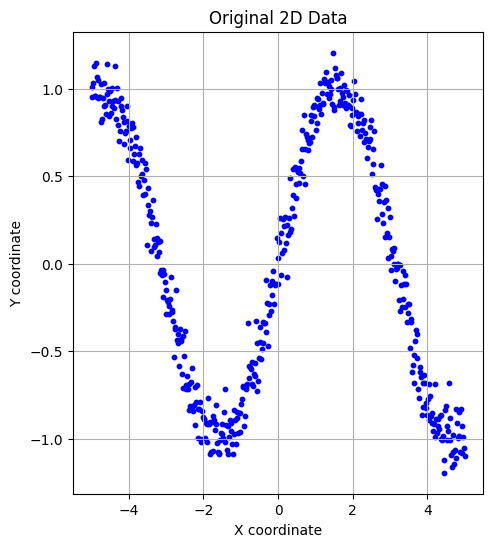

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# --- 1. Generate Simple 2D Data ---
# We'll create data that follows a sine wave pattern.
# This is simple enough to visualize and understand.
print("Step 1: Generating simple 2D data...")
np.random.seed(42)
num_samples = 500
# Generate x values and some noise to make it more realistic
X_base = np.linspace(-5, 5, num_samples)
noise = np.random.normal(0, 0.1, num_samples)
# Our 2D data will be (x, sin(x) + noise)
original_data = np.array([X_base, np.sin(X_base) + noise]).T
print(f"Data shape: {original_data.shape}") # Should be (500, 2)

# Plot 1: Original Data
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.scatter(original_data[:, 0], original_data[:, 1], c='blue', s=10)
plt.title('Original 2D Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True)




In [2]:
# --- 2. Define a Deeper Autoencoder Architecture ---
# We will add an intermediate hidden layer to both the encoder and decoder.
print("\nStep 2: Building a Deeper Autoencoder Model...")

# Define the dimensions
input_dim = 2
encoding_dim = 1 # We can still use a 1D bottleneck
intermediate_dim = 16 # More neurons to learn complex patterns

# Input Layer
input_layer = Input(shape=(input_dim,), name='Input')

# Encoder: Add a hidden layer for more capacity
encoder_hidden = Dense(intermediate_dim, activation='relu', name='Encoder-Hidden')(input_layer)
encoder_output = Dense(encoding_dim, activation='relu', name='Encoder-Output')(encoder_hidden)

# Decoder: Mirror the encoder's structure
decoder_hidden = Dense(intermediate_dim, activation='relu', name='Decoder-Hidden')(encoder_output)
decoder_output = Dense(input_dim, activation=None, name='Decoder-Output')(decoder_hidden) # Final layer can be linear

# Autoencoder Model: This model maps an input to its reconstruction
autoencoder = Model(inputs=input_layer, outputs=decoder_output, name='Autoencoder')

# We can also create a separate model for just the encoder
encoder = Model(inputs=input_layer, outputs=encoder_output, name='Encoder_Model')

# Compile the autoencoder model
autoencoder.compile(optimizer=Adam(learning_rate=0.005), loss='mean_squared_error')
autoencoder.summary()



Step 2: Building a Deeper Autoencoder Model...


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder-Hidden (Dense)          │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder-Output (Dense)          │ (None, 1)              │            17 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder-Hidden (Dense)          │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder-Output (Dense)          │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131 (524.00 B)

 Trainable params: 131 (524.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:

# --- 3. Train the Autoencoder ---
print("\nStep 3: Training the model...")
# We train the model to reconstruct the original data.
# The input (x) and the target (y) are the same.
history = autoencoder.fit(original_data, original_data,
                          epochs=100, # Train for more epochs
                          batch_size=16,
                          shuffle=True,
                          verbose=0) # Use verbose=1 to see training progress
print("Training complete.")



Step 3: Training the model...
Training complete.



Step 4: Predicting with the trained models...
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Step 5: Visualizing the results...


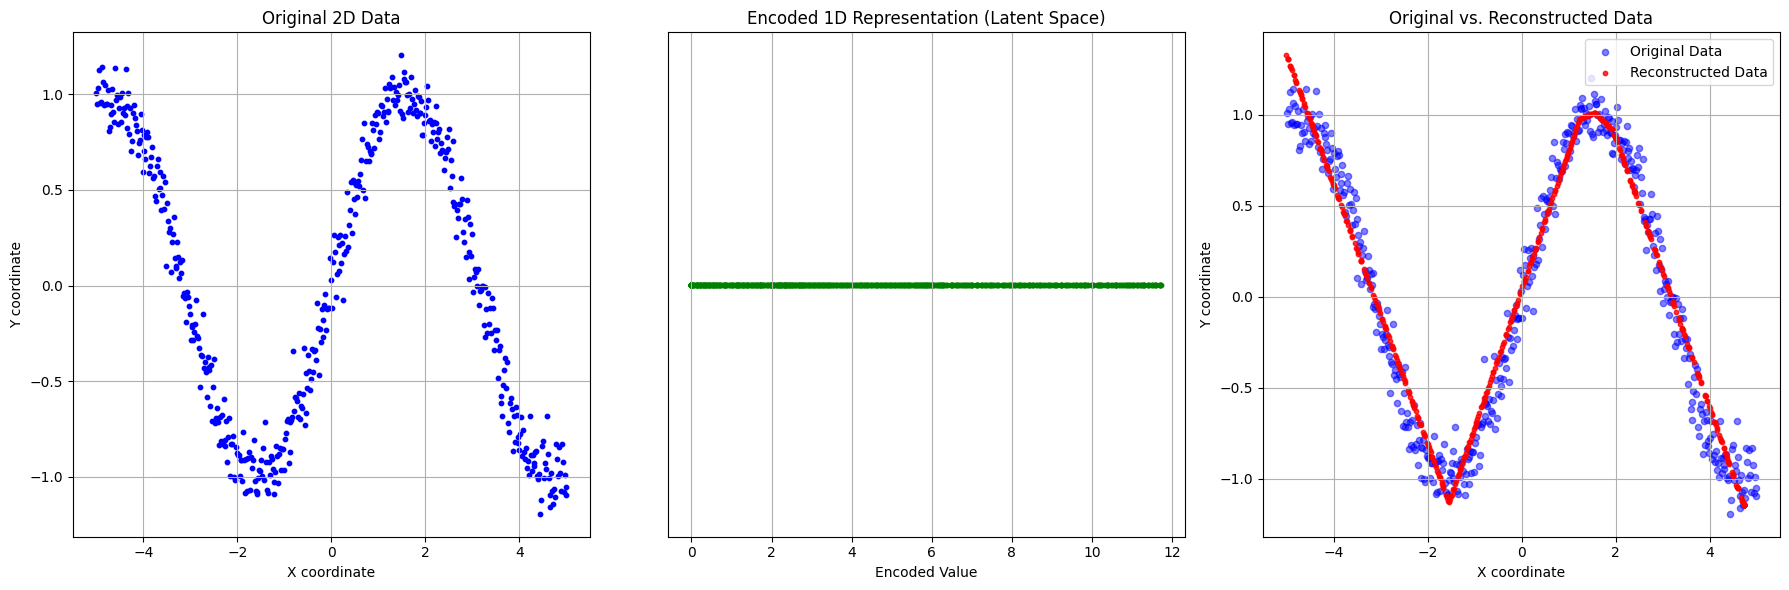

In [4]:

# --- 4. Use the Model to Encode and Decode the Data ---
print("\nStep 4: Predicting with the trained models...")
# Use the encoder model to get the compressed 1D representation
encoded_data = encoder.predict(original_data)

# Use the full autoencoder model to get the reconstructed 2D data
reconstructed_data = autoencoder.predict(original_data)

# --- 5. Visualize the Results ---
print("\nStep 5: Visualizing the results...")

# Plot 1: Original Data
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.scatter(original_data[:, 0], original_data[:, 1], c='blue', s=10)
plt.title('Original 2D Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True)

# Plot 2: Encoded (Compressed) Data
plt.subplot(1, 3, 2)
# We plot the 1D encoded data against a constant y-value to see its distribution
plt.scatter(encoded_data, np.zeros_like(encoded_data), c='green', s=10)
plt.title('Encoded 1D Representation (Latent Space)')
plt.xlabel('Encoded Value')
plt.yticks([]) # No y-axis is needed
plt.grid(True)

# Plot 3: Reconstructed Data vs. Original
plt.subplot(1, 3, 3)
plt.scatter(original_data[:, 0], original_data[:, 1], c='blue', s=20, label='Original Data', alpha=0.5)
plt.scatter(reconstructed_data[:, 0], reconstructed_data[:, 1], c='red', s=10, label='Reconstructed Data', alpha=0.8)
plt.title('Original vs. Reconstructed Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

